In [2]:
import pandas as pd
import matplotlib as plt

(326, 308)

team_id                               5
avg_attempts_distance                 4
fg_percentage                         4
two_pt_percentage                     8
three_pt_percentage                  50
                                     ..
zone_wing_3_left_attempt_rate         4
zone_wing_3_left_points_per_shot     72
zone_wing_3_right_fg_percentage      82
zone_wing_3_right_attempt_rate        4
zone_wing_3_right_points_per_shot    82
Length: 114, dtype: int64

count    326.000000
mean     118.819018
std       91.717532
min        0.000000
25%       41.000000
50%      115.000000
75%      182.750000
max      415.000000
Name: attempts, dtype: float64

<Axes: >

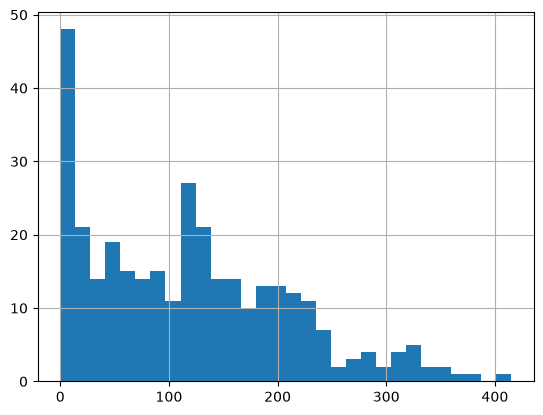

In [3]:
df = pd.read_csv("opendata-basketball/data/aggregates/acb_shotsaggregates_20252026.csv")
display(df.shape)
display(df.isna().sum()[df.isna().sum() > 0])

display(df['attempts'].describe())
display(df['attempts'].hist(bins=30))

In [4]:
thresholds = [25, 50, 75, 100]
for t in thresholds:
    n = (df['attempts'] >= t).sum()
    print(f">= {t} attempts: {n} players ({n/326*100:.1f}%)")

display(df['attempts'].quantile([0.1, 0.25, 0.5, 0.75, 0.9]))

>= 25 attempts: 261 players (80.1%)
>= 50 attempts: 235 players (72.1%)
>= 75 attempts: 202 players (62.0%)
>= 100 attempts: 178 players (54.6%)


0.10      5.00
0.25     41.00
0.50    115.00
0.75    182.75
0.90    240.00
Name: attempts, dtype: float64

In [5]:
low_attempt_players = df[df['attempts'] < 50][['attempts', 'possessions_played']].sort_values('attempts', ascending=False)
print(low_attempt_players.head(20))

     attempts  possessions_played
62         48                 349
275        46                 331
291        45                 371
82         44                 327
238        44                 352
24         44                 204
179        43                 547
19         42                 231
64         41                 187
8          41                 213
186        39                 601
151        35                 332
67         34                 445
56         33                 266
27         32                 160
57         30                 238
290        30                 241
5          30                 258
2          30                 235
322        29                 194


In [6]:
df_full = df.copy()
df = df[df['attempts'] >= 50].reset_index(drop=True)
print(df.shape)

(235, 308)


In [7]:
# Shot type distribution across the league
shot_type_cols = [c for c in df.columns if c.startswith('cst_') and c.endswith('_attempts')]
display(df[shot_type_cols].sum().sort_values(ascending=False))

# Contest level distribution
cl_cols = [c for c in df.columns if c.startswith('cl_') and c.endswith('_attempts')]
display(df[cl_cols].sum().sort_values(ascending=False))

# Zone distribution
zone_cols = [c for c in df.columns if c.startswith('zone_') and c.endswith('_attempts')]
display(df[zone_cols].sum().sort_values(ascending=False))

cst_layup_attempts              11109
cst_catch_and_shoot_attempts     7483
cst_dribble_pull_up_attempts     7186
cst_off_move_attempts            3672
cst_floater_attempts             1684
cst_hook_attempts                1257
cst_dunk_attempts                1210
cst_tip_attempts                  708
cst_stepback_attempts             657
cst_shake_and_raise_attempts      473
cst_lob_attempts                  373
cst_post_fadeaway_attempts        335
cst_heave_attempts                135
cst_leaner_attempts                92
dtype: int64

cl_plus_attempts       13770
cl_average_attempts    10320
cl_open_attempts        8229
cl_light_attempts       2625
cl_blocked_attempts     1430
dtype: int64

zone_three_attempts              15135
zone_above_break_3_attempts      11821
zone_paint_non_ra_attempts        8673
zone_restricted_area_attempts     8307
zone_wing_3_left_attempts         4046
zone_mid_range_attempts           3997
zone_wing_3_right_attempts        3960
zone_top_3_attempts               3815
zone_corner_3_attempts            3314
zone_corner_3_left_attempts       1765
zone_corner_3_right_attempts      1549
zone_other_attempts                889
zone_far_attempts                  141
zone_backcourt_attempts            125
dtype: int64

**Player Inclusion Threshold**

Minimum 50 attempts required for inclusion in analysis. 
Players below this threshold (91 of 326, ~28%) lack sufficient shot volume to construct a reliable profile across dimensions. 
Low-attempt players were verified to also have low possessions_played, confirming they are non-rotation players rather than genuine 
non-shooting role players. Working dataset: 235 players.

**Classification Types**


Shot Types:

    - cst_layup_attempts ✓
    - cst_dunk_attempts ✓
        - cst_lob_attempts - group into dunks, profile of a player who will attempt lobs is by athleticism similar to a dunker
        - cst_tip_attempts - group into dunks, profile of a player who will attempt tips is by athleticism similar to a dunker
    - cst_catch_and_shoot_attempts ✓
    - cst_perimeter_self_created ✓
        - cst_dribble_pull_up_attempts - group into perimeter_self_created, regardless of final shot type choice, the method to reaching it is ultimately the same, perimeter-isolation
        - cst_stepback_attempts - group into perimeter_self_created, regardless of final shot type choice, the method to reaching it is ultimately the same, perimeter-isolation
    - cst_post_self_created ✓
        - cst_shake_and_raise_attempts - group into post_self_created, regardless of final shot type choice, the method to reaching it is ultimately the same, post-work
        - cst_post_fadeaway_attempts - group into post_self_created, regardless of final shot type choice, the method to reaching it is ultimately the same, post-work
    - cst_off_move_attempts ✓
    - cst_floater_attempts ✓
        - cst_hook_attempts - group into floater, differentiation can be ambiguous and shot types are similar enough
    - cst_heave_attempts ✖ - too sparse and unspecialized to include
    - cst_leaner_attempts ✖ - too sparse and difficult to define to include


Contest Types:

    - cl_plus_attempts ✓
    - cl_average_attempts ✓
    - cl_open_attempts ✓
    - cl_light_attempts ✓
    - cl_blocked_attempts ✓


Zones:

    - zone_three_attempts ✖ - aggregation and thus excluded
    - zone_above_break_3_attempts ✖ - aggregation and thus excluded
    - zone_paint_non_ra_attempts ✓
    - zone_restricted_area_attempts ✓
    - zone_wing_3_left_attempts ✓
    - zone_mid_range_attempts ✓
    - zone_wing_3_right_attempts ✓
    - zone_top_3_attempts ✓
    - zone_corner_3_attempts ✖ - aggregation and thus excluded
    - zone_corner_3_left_attempts ✓
    - zone_corner_3_right_attempts ✓
    - zone_other_attempts ✖ - catch-all, unclassifiable
    - zone_far_attempts ✖ - too sparce and uspecialized to include
    - zone_backcourt_attempts ✖ - too sparce and uspecialized to include

In [8]:
import numpy as np
import pandas as pd

GROUPS = {
    'cst_': {  # shot type
        'layup':                  ['layup'],
        'dunk_finish':            ['dunk', 'lob', 'tip'],
        'catch_and_shoot':        ['catch_and_shoot'],
        'self_created_perimeter': ['dribble_pull_up', 'stepback', 'shake_and_raise'],
        'post':                   ['post_fadeaway'],
        'off_move':               ['off_move'],
        'floater_hook':           ['floater', 'hook'],
    },
    'cl_': {k: [k] for k in ['open', 'light', 'average', 'plus', 'blocked']},
    'zone_': {k: [k] for k in ['restricted_area', 'paint_non_ra', 'mid_range',
                               'corner_3_left', 'corner_3_right',
                               'wing_3_left', 'wing_3_right', 'top_3']},
}

def build_buckets(df, prefix, groups):
    att, pts = {}, {}
    for name, members in groups.items():
        att[name] = df[[f'{prefix}{m}_attempts' for m in members]].fillna(0).sum(axis=1)
        pts[name] = df[[f'{prefix}{m}_total_points' for m in members]].fillna(0).sum(axis=1)
    return pd.DataFrame(att), pd.DataFrame(pts)

buckets = {p: build_buckets(df, p, g) for p, g in GROUPS.items()}

# Reconciliation: what fraction of each player's attempts does each dimension cover?
for p, (att, _) in buckets.items():
    cov = att.sum(axis=1) / df['attempts']
    print(p, cov.describe()[['min', 'mean', 'max']].round(3).to_dict())

cst_ {'min': 0.886, 'mean': 0.971, 'max': 1.0}
cl_ {'min': 0.902, 'mean': 0.976, 'max': 1.0}
zone_ {'min': 0.894, 'mean': 0.969, 'max': 1.0}


In [10]:
def concentration(att):
    share = att.div(att.sum(axis=1), axis=0)
    k = share.shape[1]
    hhi = (share ** 2).sum(axis=1)
    hhi_norm = (hhi - 1 / k) / (1 - 1 / k)          # 0 = uniform, 1 = all in one bucket
    ent = -(share * np.log(share.where(share > 0))).sum(axis=1)
    ent_norm = ent / np.log(k)                       # 1 = uniform, 0 = fully concentrated
    return share, hhi_norm, ent_norm

shares, conc = {}, pd.DataFrame(index=df.index)
for p, (att, _) in buckets.items():
    shares[p], conc[f'{p}hhi'], conc[f'{p}ent'] = concentration(att)
    print(shares[p], conc[f'{p}hhi'], conc[f'{p}ent'])


        layup  dunk_finish  catch_and_shoot  self_created_perimeter      post  \
0    0.279412     0.044118         0.220588                0.191176  0.044118   
1    0.603774     0.037736         0.094340                0.113208  0.018868   
2    0.349593     0.024390         0.243902                0.170732  0.008130   
3    0.146199     0.017544         0.339181                0.140351  0.029240   
4    0.330000     0.016667         0.106667                0.396667  0.016667   
..        ...          ...              ...                     ...       ...   
230  0.113537     0.013100         0.113537                0.427948  0.004367   
231  0.424242     0.020202         0.121212                0.222222  0.000000   
232  0.198758     0.031056         0.397516                0.186335  0.000000   
233  0.375000     0.104167         0.437500                0.020833  0.000000   
234  0.094488     0.031496         0.251969                0.244094  0.007874   

     off_move  floater_hook